nn_2 0 1.3517733812332153
nn_2 500 0.39566275477409363
nn_2 1000 0.3351561427116394
nn_2 1500 0.32101768255233765
nn_2 2000 0.31854715943336487
nn_2 2500 0.3176713287830353
nn_2x2 0 1.0238673686981201
nn_2x2 500 0.302253782749176
nn_2x2 1000 0.28931882977485657
nn_2x2 1500 0.28683891892433167
nn_2x2 2000 0.286149799823761
nn_2x2 2500 0.28613004088401794
nn_2 0 1.182448148727417
nn_2 500 0.30263468623161316
nn_2 1000 0.28989946842193604
nn_2 1500 0.284404456615448
nn_2 2000 0.2841953635215759
nn_2 2500 0.2841867208480835
nn_2x2 0 1.0484329462051392
nn_2x2 500 0.22412168979644775
nn_2x2 1000 0.22412623465061188
nn_2x2 1500 0.22419188916683197
nn_2x2 2000 0.22414125502109528
nn_2x2 2500 0.22415390610694885
nn_2 0 1.3517733812332153
nn_2 500 0.39566275477409363
nn_2 1000 0.3351561427116394
nn_2 1500 0.32101768255233765
nn_2 2000 0.31854715943336487
nn_2 2500 0.3176713287830353
nn_2x2 0 1.0238673686981201
nn_2x2 500 0.302253782749176
nn_2x2 1000 0.28931882977485657
nn_2x2 1500 0.28683891892

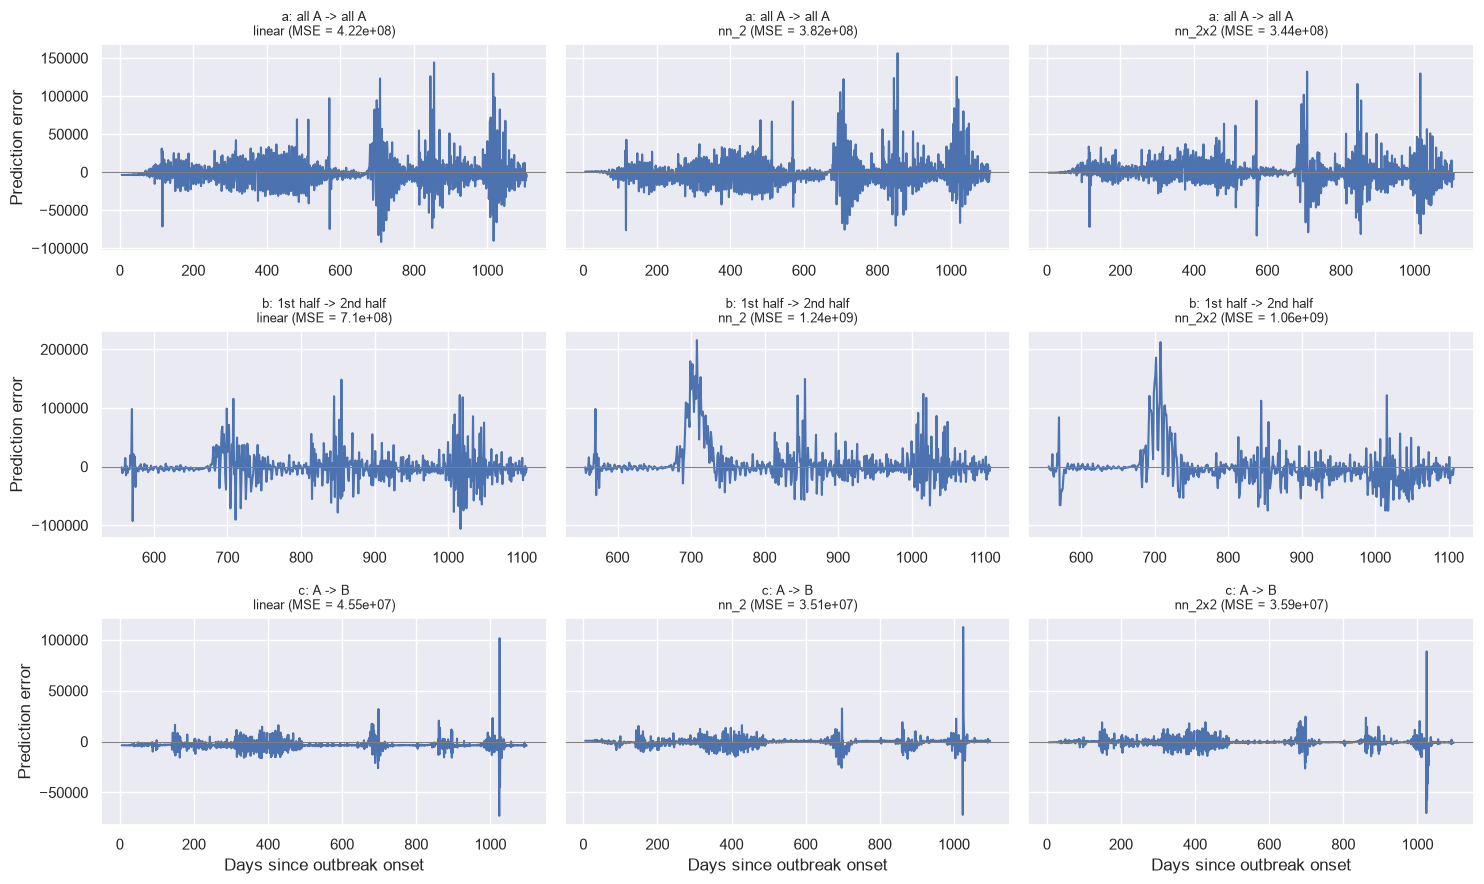

In [17]:
# HW 9 Problem 2 with neural net 
# !pip install torch
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.linear_model as lm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
sns.set()

# bring in the data set
df=pd.read_csv("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv")

def model(country):
    row = df[df['Country/Region'] == country]
    cumul = row.iloc[0,4:].to_numpy(dtype=float)
    daily = np.diff(cumul,prepend = 0) # find daily cases by taking difference of cases between days
    fd = np.argmax(daily>0) #find first day
    y = daily[fd:]
    #build regression equation
    T = len(y)
    Y = y[5:]
    X = np.column_stack([y[5-k:T-k] for k in range(1,6)])
    return X, Y

def fit_predict(model_name,Xtrn,Ytrn,Xtest,seed=0,itrn=3000,lr=1e-2):
    if model_name=='linear':
        return LinearRegression().fit(Xtrn,Ytrn).predict(Xtest)
    torch.manual_seed(seed)
    #normalize the data 
    sx = StandardScaler().fit(Xtrn)
    sy = StandardScaler().fit(Ytrn.reshape(-1,1))
    #convert to pytorch tensors
    xtrn = torch.from_numpy(sx.transform(Xtrn)).float()
    ytrn = torch.from_numpy(sy.transform(Ytrn.reshape(-1,1))).float()
    xtest = torch.from_numpy(sx.transform(Xtest)).float()

    if model_name == 'nn_2': #2 hidden nodes
        model = torch.nn.Sequential(
            torch.nn.Linear(5,2),
            torch.nn.ReLU(),
            torch.nn.Linear(2,1),)
    else: #4 hidden nodes over 2 layers
        model = torch.nn.Sequential( 
            torch.nn.Linear(5, 2),
            torch.nn.ReLU(),
            torch.nn.Linear(2, 2),
            torch.nn.ReLU(),
            torch.nn.Linear(2, 1),)
    loss_fn = torch.nn.MSELoss() #means squared error loss
    opt = torch.optim.Adam(model.parameters(),lr=lr) 

    for t in range(itrn):
        opt.zero_grad() #zero gradients 
        loss = loss_fn(model(xtrn),ytrn) #predict on training data and find error
        loss.backward() #backward propogation
        opt.step() #optimize weights

        if t % 500==0:
            print(model_name,t,loss.item())

    with torch.no_grad():
        pred = model(xtest).numpy()
    return sy.inverse_transform(pred).ravel()
                                      
#find parameters of country A and country B
XA,YA = model('Brazil')
XB,YB = model('Peru')
h = len(YA) // 2 #for splitting halves

models = ['linear', 'nn_2', 'nn_2x2']

# a. fit on all of A, apply to all of A
err_a = {m: YA - fit_predict(m, XA, YA, XA) for m in models}

# b. fit on the first half of A, apply to the second half
err_b = {m: YA[h:] - fit_predict(m, XA[:h], YA[:h], XA[h:]) for m in models}

# c. fit on A, apply to B
err_c = {m: YB - fit_predict(m, XA, YA, XB) for m in models}

# Table of mean squared errors: one row per scenario, one column per model
table = pd.DataFrame(
    [[np.mean(err[m]**2) for m in models] for err in (err_a, err_b, err_c)],
    columns=models,
    index=['a: all A -> all A', 'b: 1st half -> 2nd half', 'c: A -> B']
)
print(table)


#make plots
scen = [('a: all A -> all A', err_a, np.arange(5, 5 + len(YA))),
        ('b: 1st half -> 2nd half', err_b, np.arange(5 + h, 5 + len(YA))),
        ('c: A -> B', err_c, np.arange(5, 5 + len(YB)))]

fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharey='row')
for i, (sname, errs, t) in enumerate(scen):
    for j, m in enumerate(models):
        ax = axes[i, j]
        ax.plot(t, errs[m])
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.set_title(f"{sname}\n{m} (MSE = {np.mean(errs[m]**2):.3g})", fontsize=9)
        if j == 0:
            ax.set_ylabel('Prediction error')
        if i == 2:
            ax.set_xlabel('Days since outbreak onset')
plt.tight_layout()
plt.show()

## Discussion

**Scenario A:** All of Brazil was applied to all of Brazil. Both neural net models yielded a lower mean squared error than the linear regression with the 2x2 model reducing the error by close to 20%.

**Scenario B:** 1st Half of Brazil applied on 2nd Half of Brazil. In this case the linear regression had the lowest mean squared error by 50%-75%. It is likely due to the fact that the amount of cases from the first half is much lower than the amounts seen in the second half. The model is trying to predict outside of its original range.

**Scenario C:** All of Brazil was applied on all of Peru. This test yielded similar results to scenario A but both neural net models seem to have gotten a similar mean squared error.

**Overall:** A more flexible model with more layers of nodes generally was able to fit the training data better but the results on a new data set were mixed.